In [1]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [2]:
load_gmx_plumed()

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import subprocess
import os
from contextlib import contextmanager
import re
import pandas
import pathlib

In [4]:
%cd /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish

/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish


/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/Compiler/gcccore/ipykernel/2025a/lib/python3.12/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


## 🔬 SMOG POTENTIAL ENERGY DISTRIBUTIONS

Exports and visualizes temperature-dependent potential energy distributions 📊  
for comparative analysis across SMOG systems.

**Systems:** 3PRG, 6ONJ, 6ONI 🧬  
**Colormap:** RdBu (dark-only, cold → hot) 🎨


/tmp/ipykernel_2517586/1457038893.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("RdBu")
/tmp/ipykernel_2517586/1457038893.py:81: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  sm = cm.ScalarMappable(norm=norm, cmap=cm.get_cmap("RdBu"))
/tmp/ipykernel_2517586/1457038893.py:99: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


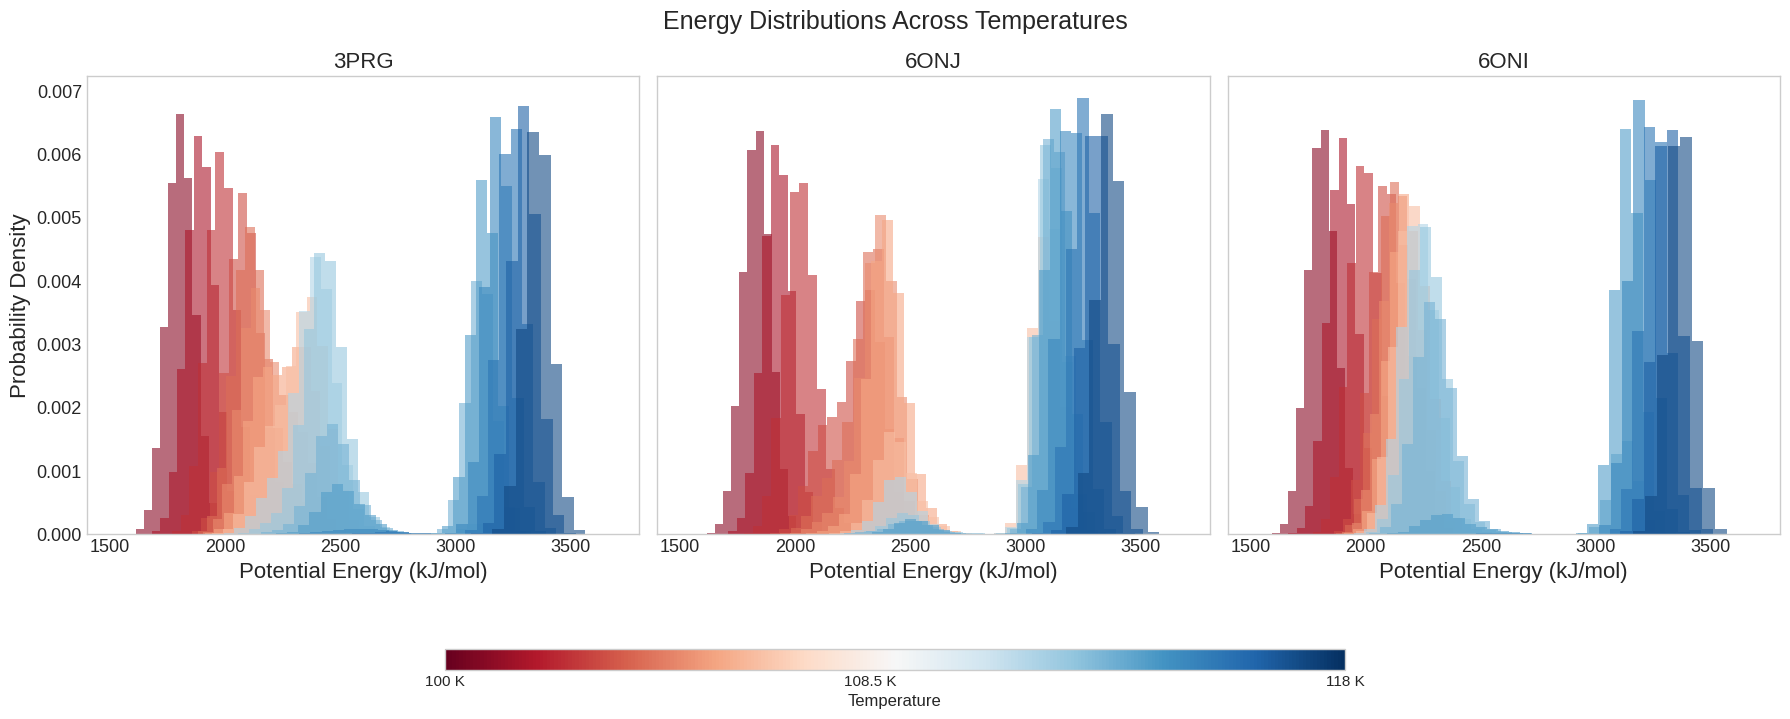

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import os
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# =========================
# 🔧 STYLE (BUILT-IN ONLY)
# =========================
plt.style.use("seaborn-v0_8-whitegrid")

# =========================
# 🔧 SIZE TOGGLES
# =========================
FIGSIZE = (18, 6)
AXIS_LABEL_SIZE = 16
TITLE_SIZE      = 16
TICK_SIZE       = 13
LEGEND_FONT     = 11

BINS  = 100
ALPHA = 0.6
X_LIM = (1400, 3800)

# =========================
# 📂 SYSTEMS & TEMPERATURES
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]
temps = [100,102,104,106,106.5,107,107.5,108,108.5,109,109.5,110,112,114,116,118]

# =========================
# 🎨 DARK-ONLY RdBu (NO LIGHT MIDDLE)
# =========================
cmap = cm.get_cmap("RdBu")
n = len(temps)
half = n // 2

dark_blues = cmap(np.linspace(0.05, 0.35, half))
dark_reds  = cmap(np.linspace(0.65, 0.95, n - half))
colors = np.vstack([dark_blues, dark_reds])

# =========================
# 📊 PLOTTING (NO GRIDS)
# =========================
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, sharex=True, sharey=True)
#for ax in axes:
#    ax.set_facecolor("#e6e6e6")   # darker grey inside panels only

for ax, system in zip(axes, systems):
    for T, color in zip(temps, colors):
        fname = os.path.join(system, str(T), "potential.xvg")

        if not os.path.isfile(fname):
            print(f"⚠️ Missing: {fname}")
            continue

        data = np.loadtxt(fname, comments=["@", "#"])
        E = data[:, 1]

        ax.hist(
            E,
            bins=BINS,
            density=True,
            alpha=ALPHA,
            color=color,
            edgecolor="none"
        )

    ax.set_title(system, fontsize=TITLE_SIZE)
    ax.set_xlabel("Potential Energy (kJ/mol)", fontsize=AXIS_LABEL_SIZE)
    ax.set_xlim(*X_LIM)
    ax.tick_params(axis="both", labelsize=TICK_SIZE)
    ax.grid(False)

axes[0].set_ylabel("Probability Density", fontsize=AXIS_LABEL_SIZE)

# =========================
# 🎨 COLORBAR BELOW (NO OVERLAP)
# =========================
norm = mcolors.Normalize(vmin=min(temps), vmax=max(temps))
sm = cm.ScalarMappable(norm=norm, cmap=cm.get_cmap("RdBu"))
sm.set_array([])

# ✅ Put colorbar in its OWN axis below everything
cax = fig.add_axes([0.25, -0.12, 0.5, 0.035])  
cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")

mid_temp = temps[len(temps)//2]
cbar.set_ticks([temps[0], mid_temp, temps[-1]])
cbar.set_ticklabels([f"{temps[0]} K", f"{mid_temp} K", f"{temps[-1]} K"])
cbar.ax.tick_params(labelsize=LEGEND_FONT)
cbar.set_label("Temperature", fontsize=LEGEND_FONT + 1)

# =========================
# 🏷️ TITLE
# =========================
fig.suptitle("Energy Distributions Across Temperatures", fontsize=TITLE_SIZE + 2)

plt.tight_layout()
plt.show()


# CSV EXPORT FOR DOWNSTREAM PLOTTING
description: raw SMOG potential energies exported for reproducible figure generation
systems: [3PRG, 6ONJ, 6ONI]
temperature_range_K: 100–118
input_format: SYSTEM/temperature/potential.xvg
output_files:
  3PRG: SMOG_Potential_energy_3PRG.csv
  6ONJ: SMOG_Potential_energy_6ONJ.csv
  6ONI: SMOG_Potential_energy_6ONI.csv
data_fields: [system, temperature_K, energy_kJ_mol]


In [6]:
import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------------------
# **BASE WORKING DIRECTORY**
# ------------------------------------------------------------------------------------------
BASE = "/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish"
os.chdir(BASE)

# ------------------------------------------------------------------------------------------
# **SYSTEMS AND TEMPERATURES**
# ------------------------------------------------------------------------------------------
systems = ["3PRG", "6ONJ", "6ONI"]

temps = [
    100, 102, 104, 106, 106.5, 107, 107.5, 108,
    108.5, 109, 109.5, 110, 112, 114, 116, 118
]

# ------------------------------------------------------------------------------------------
# **OUTPUT ROOT DIRECTORY**
# ------------------------------------------------------------------------------------------
OUTROOT = "/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures"
os.makedirs(OUTROOT, exist_ok=True)

# ------------------------------------------------------------------------------------------
# **MAIN EXPORT LOOP (ONE CSV PER SYSTEM)**
# ------------------------------------------------------------------------------------------
for system in systems:

    print(f"\n🚀 PROCESSING SYSTEM: {system}")

    system_outdir = os.path.join(OUTROOT, system)
    os.makedirs(system_outdir, exist_ok=True)

    rows = []

    for T in temps:
        fname = os.path.join(system, str(T), "potential.xvg")

        if not os.path.isfile(fname):
            print(f"⚠️  MISSING FILE: {fname}")
            continue

        data = np.loadtxt(fname, comments=["@", "#"])
        energies = data[:, 1]

        for e in energies:
            rows.append((system, T, e))

    df = pd.DataFrame(
        rows,
        columns=["system", "temperature_K", "energy_kJ_mol"]
    )

    outcsv = os.path.join(system_outdir, f"SMOG_Potential_energy_{system}.csv")
    df.to_csv(outcsv, index=False)

    print(f"✅ WRITTEN: {outcsv}")
    print(f"📊 TOTAL ROWS: {len(df)}")

print("\n🎯 ALL SYSTEMS PROCESSED SUCCESSFULLY")


🚀 PROCESSING SYSTEM: 3PRG
✅ WRITTEN: /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/SMOG_Potential_energy_3PRG.csv
📊 TOTAL ROWS: 3360016

🚀 PROCESSING SYSTEM: 6ONJ
✅ WRITTEN: /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/6ONJ/SMOG_Potential_energy_6ONJ.csv
📊 TOTAL ROWS: 3360016

🚀 PROCESSING SYSTEM: 6ONI
✅ WRITTEN: /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/6ONI/SMOG_Potential_energy_6ONI.csv
📊 TOTAL ROWS: 3360016

🎯 ALL SYSTEMS PROCESSED SUCCESSFULLY


## 🔥 SPECIFIC HEAT (Cᵥ) FROM WHAM

Plots temperature-dependent specific heat curves derived from WHAM analysis 📊  
for comparative thermodynamic assessment across SMOG systems.

**Systems:** 3PRG, 6ONJ, 6ONI 🧬  
**Method:** WHAM-derived Cᵥ(T)  
**Comparison:** shared axes for direct contrast 🎯


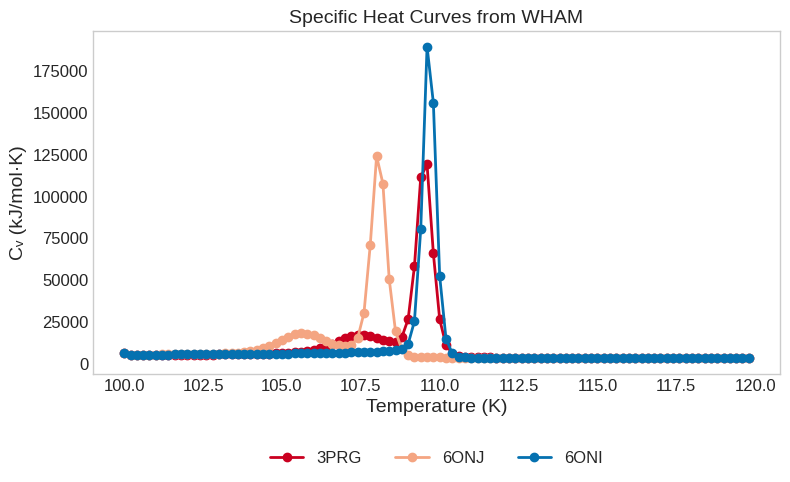

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import os

# =========================
# 🔧 SIZE TOGGLES
# =========================
FIGSIZE = (8, 5)
AXIS_LABEL_SIZE = 14
TITLE_SIZE      = 14
TICK_SIZE       = 12
LINE_WIDTH      = 2.0

# =========================
# 📂 SYSTEMS & COLORS
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]
colors = {
    "3PRG": "#ca0020",   # red
    "6ONJ": "#f4a582",   # salmon
    "6ONI": "#0571b0"    # blue
}

# =========================
# 📊 PLOTTING
# =========================
fig, ax = plt.subplots(figsize=FIGSIZE)

for system in systems:
    fname = os.path.join("Wham", system, "cv.dat")

    if not os.path.isfile(fname):
        print(f"⚠️ Missing: {fname}")
        continue

    cv = np.loadtxt(fname)
    T, Cv = cv[:, 0], cv[:, 1]

    ax.plot(
        T, Cv,
        color=colors[system],
        lw=LINE_WIDTH,
        marker="o",
        label=system
    )

# =========================
# 🏷️ LABELS & STYLE
# =========================
ax.set_xlabel("Temperature (K)", fontsize=AXIS_LABEL_SIZE)
ax.set_ylabel("Cᵥ (kJ/mol·K)", fontsize=AXIS_LABEL_SIZE)
ax.set_title("Specific Heat Curves from WHAM", fontsize=TITLE_SIZE)

ax.tick_params(axis="both", labelsize=TICK_SIZE)

# ✅ NO GRIDS
ax.grid(False)

# =========================
# 📍 LEGEND AT BOTTOM
# =========================
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=False,
    fontsize=TICK_SIZE
)

plt.tight_layout()
plt.show()


## 🔥 SPECIFIC HEAT DATA (WHAM)

Copies WHAM-derived specific heat output files for standardized storage and reuse 📁  
Files are renamed by system for clarity and reproducibility.

**Systems:** 3PRG, 6ONJ, 6ONI 🧬  
**Data:** WHAM Cᵥ(T) output  
**Output:** `{system}_cv.dat` (per system)


In [10]:
import os
import shutil

# =========================
# 📂 SYSTEMS
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]

# =========================
# 📁 PATHS
# =========================
WHAM_ROOT = "Wham"
OUTROOT = "/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures"

os.makedirs(OUTROOT, exist_ok=True)

# =========================
# 🔁 COPY LOOP
# =========================
for system in systems:
    src = os.path.join(WHAM_ROOT, system, "cv.dat")

    if not os.path.isfile(src):
        print(f"⚠️ Missing: {src}")
        continue

    system_outdir = os.path.join(OUTROOT, system)
    os.makedirs(system_outdir, exist_ok=True)

    dst = os.path.join(system_outdir, f"{system}_cv.dat")
    shutil.copy2(src, dst)

    print(f"✅ Copied: {src} → {dst}")

print("\n🎯 WHAM Cᵥ files copied and renamed successfully")


✅ Copied: Wham/3PRG/cv.dat → /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/3PRG_cv.dat
✅ Copied: Wham/6ONJ/cv.dat → /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/6ONJ/6ONJ_cv.dat
✅ Copied: Wham/6ONI/cv.dat → /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/6ONI/6ONI_cv.dat

🎯 WHAM Cᵥ files copied and renamed successfully


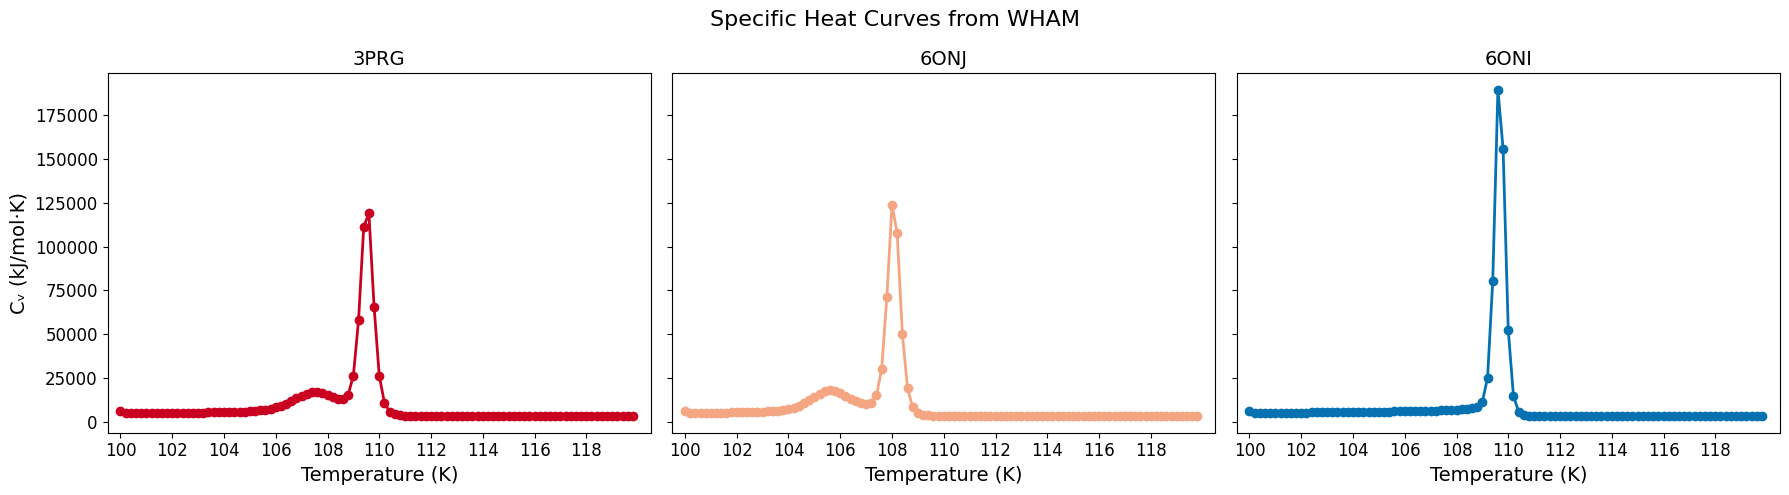

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import os

# =========================
# 🔧 SIZE TOGGLES
# =========================
FIGSIZE = (18, 5)
AXIS_LABEL_SIZE = 14
TITLE_SIZE      = 14
TICK_SIZE       = 12
LINE_WIDTH      = 2.0

# =========================
# 📂 SYSTEMS & COLORS
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]
colors = {
    "3PRG": "#ca0020",   # red
    "6ONJ": "#f4a582",   # salmon
    "6ONI": "#0571b0"    # blue
}

# =========================
# 📊 PLOTTING (SIDE BY SIDE)
# =========================
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, sharey=True)

for ax, system in zip(axes, systems):
    fname = os.path.join("Wham", system, "cv.dat")

    if not os.path.isfile(fname):
        print(f"⚠️ Missing: {fname}")
        continue

    cv = np.loadtxt(fname)
    T, Cv = cv[:, 0], cv[:, 1]

    ax.plot(
        T, Cv,
        color=colors[system],
        lw=LINE_WIDTH,
        marker="o"
    )

    ax.set_title(system, fontsize=TITLE_SIZE)
    ax.set_xlabel("Temperature (K)", fontsize=AXIS_LABEL_SIZE)
    ax.set_xticks(np.arange(100, 120, 2))
    ax.set_xlim(99.5, 120.5)
    ax.tick_params(axis="both", labelsize=TICK_SIZE)
    ax.grid(False)


# Shared Y label
axes[0].set_ylabel("Cᵥ (kJ/mol·K)", fontsize=AXIS_LABEL_SIZE)

# =========================
# 🏷️ TITLE
# =========================
fig.suptitle("Specific Heat Curves from WHAM", fontsize=TITLE_SIZE + 2)

plt.tight_layout()
plt.show()


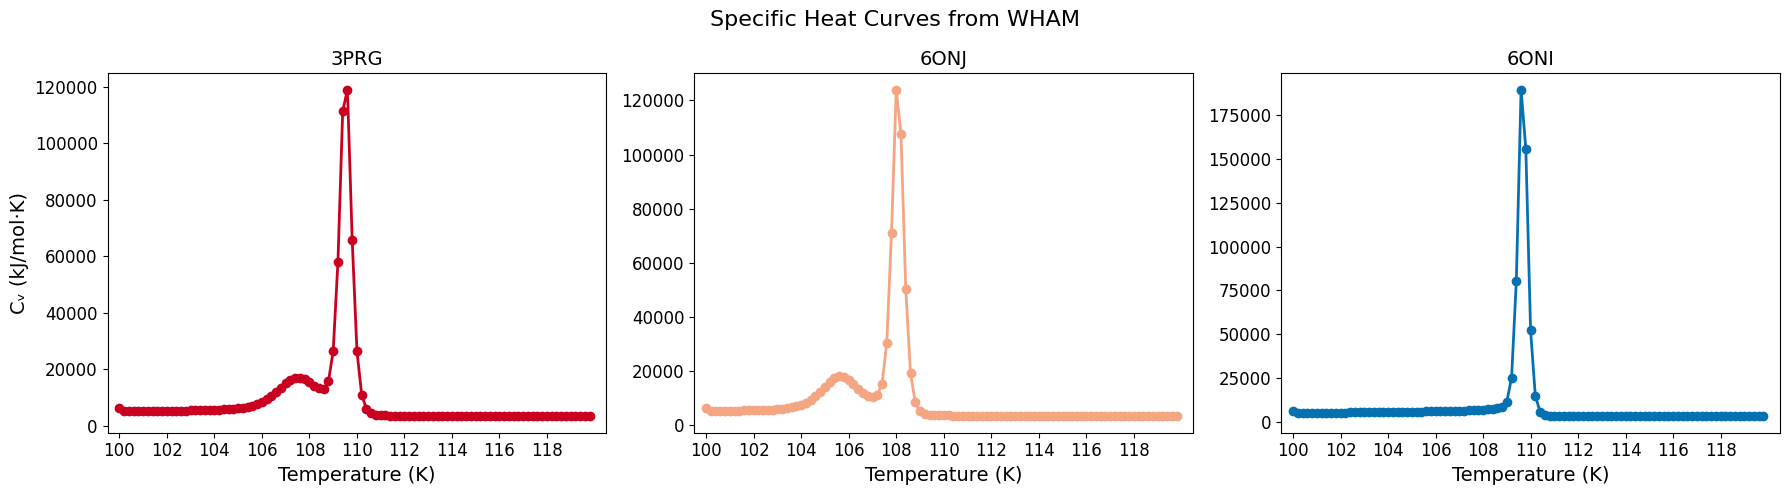

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os

# =========================
# 🔧 SIZE TOGGLES
# =========================
FIGSIZE = (18, 5)
AXIS_LABEL_SIZE = 14
TITLE_SIZE      = 14
TICK_SIZE       = 12
LINE_WIDTH      = 2.0

# =========================
# 📂 SYSTEMS & COLORS
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]
colors = {
    "3PRG": "#ca0020",   # red
    "6ONJ": "#f4a582",   # salmon
    "6ONI": "#0571b0"    # blue
}

# =========================
# 📊 PLOTTING (SIDE BY SIDE, INDEPENDENT Y-SCALE)
# =========================
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE)  # ✅ NO sharey=True

for ax, system in zip(axes, systems):
    fname = os.path.join("Wham", system, "cv.dat")

    if not os.path.isfile(fname):
        print(f"⚠️ Missing: {fname}")
        continue

    cv = np.loadtxt(fname)
    T, Cv = cv[:, 0], cv[:, 1]

    ax.plot(
        T, Cv,
        color=colors[system],
        lw=LINE_WIDTH,
        marker="o"
    )

    ax.set_title(system, fontsize=TITLE_SIZE)
    ax.set_xlabel("Temperature (K)", fontsize=AXIS_LABEL_SIZE)
    ax.set_xticks(np.arange(100, 120, 2))
    ax.set_xlim(99.5, 120.5)
    ax.tick_params(axis="both", labelsize=TICK_SIZE)
    ax.grid(False)

# Shared Y label (label only, not scale)
axes[0].set_ylabel("Cᵥ (kJ/mol·K)", fontsize=AXIS_LABEL_SIZE)

# =========================
# 🏷️ TITLE
# =========================
fig.suptitle("Specific Heat Curves from WHAM", fontsize=TITLE_SIZE + 2)

plt.tight_layout()
plt.show()


## 🧬 DISTRIBUTION OF NATIVE CONTACTS (Q)

Aggregated probability distributions of the native contact fraction (Q)  
computed across all simulated temperatures.

**Systems:** 3PRG, 6ONJ, 6ONI  
**Metric:** Q (native contacts)  
**Data:** combined e–Q samples across temperatures  
**Comparison:** shared y-axis for cross-system contrast


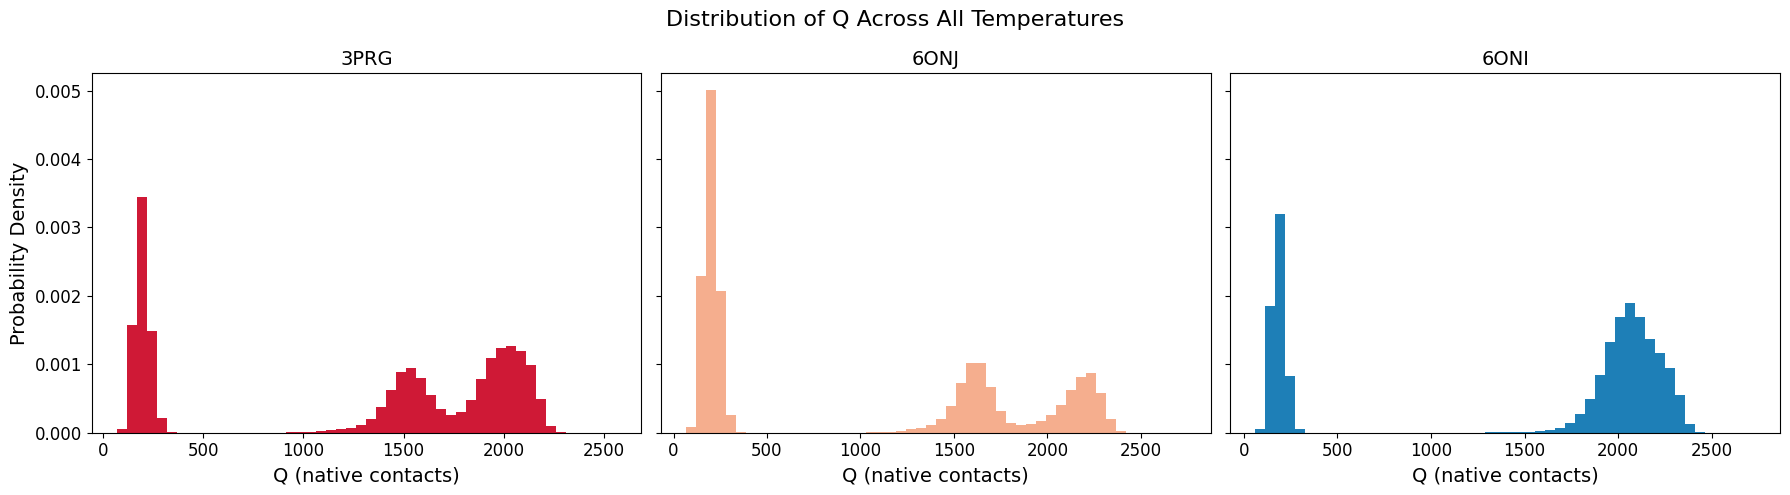

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# =========================
# 🔧 SIZE TOGGLES
# =========================
FIGSIZE = (18, 5)
AXIS_LABEL_SIZE = 14
TITLE_SIZE      = 14
TICK_SIZE       = 12
BINS            = 50
ALPHA           = 0.9

# =========================
# 📂 SYSTEMS, TEMPS & COLORS
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]
temps = [100, 102, 104, 106, 106.5, 107, 107.5, 108, 108.5, 109, 109.5, 110, 112, 114, 116, 118]

colors = {
    "3PRG": "#ca0020",   # red
    "6ONJ": "#f4a582",   # salmon
    "6ONI": "#0571b0"    # blue
}

# =========================
# ✅ DEFINE read_eQ FUNCTION
# =========================
def read_eQ(folder):
    fname = os.path.join(folder, "e-Q.dat")
    data = np.loadtxt(fname)
    df = pd.DataFrame(data, columns=["E", "Q"])
    return df

# =========================
# 📊 PLOTTING (SIDE BY SIDE)
# =========================
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, sharey=True)

for ax, system in zip(axes, systems):

    all_frames = []

    for T in temps:
        folder = os.path.join(system, str(T))
        fname = os.path.join(folder, "e-Q.dat")

        if os.path.exists(fname):
            df = read_eQ(folder)
            all_frames.append(df)

    if not all_frames:
        continue

    frames = pd.concat(all_frames, ignore_index=True)

    ax.hist(
        frames["Q"],
        bins=BINS,
        density=True,
        alpha=ALPHA,
        color=colors[system],
        edgecolor="none"
    )

    ax.set_title(system, fontsize=TITLE_SIZE)
    ax.set_xlabel("Q (native contacts)", fontsize=AXIS_LABEL_SIZE)
    ax.tick_params(axis="both", labelsize=TICK_SIZE)
    ax.grid(False)   # ✅ NO GRIDS

# Shared Y label
axes[0].set_ylabel("Probability Density", fontsize=AXIS_LABEL_SIZE)

# =========================
# 🏷️ TITLE
# =========================
fig.suptitle("Distribution of Q Across All Temperatures", fontsize=TITLE_SIZE + 2)

plt.tight_layout()
plt.show()


## 🧬 NATIVE CONTACT (Q) DATA EXPORT

Exports per-frame native contact fractions (Q) aggregated across all temperatures  
for reproducible analysis and figure regeneration.

**Systems:** 3PRG, 6ONJ, 6ONI  
**Data:** e–Q samples combined across temperatures  
**Output:** `Q_distribution_{system}.csv` (per system)


In [5]:
import numpy as np
import pandas as pd
import os

# =========================
# 📂 SYSTEMS & TEMPERATURES
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]
temps = [100, 102, 104, 106, 106.5, 107, 107.5, 108,
         108.5, 109, 109.5, 110, 112, 114, 116, 118]

# =========================
# 📁 OUTPUT ROOT
# =========================
OUTROOT = "/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures"
os.makedirs(OUTROOT, exist_ok=True)

# =========================
# 🔁 EXPORT LOOP
# =========================
for system in systems:

    rows = []

    for T in temps:
        fname = os.path.join(system, str(T), "e-Q.dat")

        if not os.path.isfile(fname):
            continue

        data = np.loadtxt(fname)

        for E, Q in data:
            rows.append({
                "system": system,
                "temperature_K": T,
                "E": E,
                "Q": Q
            })

    if not rows:
        print(f"⚠️ No data found for {system}")
        continue

    df = pd.DataFrame(rows)

    system_outdir = os.path.join(OUTROOT, system)
    os.makedirs(system_outdir, exist_ok=True)

    outcsv = os.path.join(system_outdir, f"Q_distribution_{system}.csv")
    df.to_csv(outcsv, index=False)

    print(f"✅ Written: {outcsv} ({len(df)} rows)")

print("\n🎯 Q-distribution CSV export complete")


✅ Written: /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/Q_distribution_3PRG.csv (3360016 rows)
✅ Written: /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/6ONJ/Q_distribution_6ONJ.csv (3360016 rows)
✅ Written: /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/6ONI/Q_distribution_6ONI.csv (3360016 rows)

🎯 Q-distribution CSV export complete
